Make the necessary import

In [1]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

%matplotlib inline

pokemon = pd.read_csv('./bar_chart_datasets/pokemon.csv')

In [2]:
print(pokemon.shape)

(807, 14)


In [3]:
pokemon.head()

,id,species,generation_id,height,weight,base_experience,type_1,type_2,hp,attack,defense,speed,special-attack,special-defense
0,1,bulbasaur,1,0.7,6.9,64,grass,poison,45,49,49,45,65,65
1,2,ivysaur,1,1.0,13.0,142,grass,poison,60,62,63,60,80,80
2,3,venusaur,1,2.0,100.0,236,grass,poison,80,82,83,80,100,100
3,4,charmander,1,0.6,8.5,62,fire,NaN,39,52,43,65,60,50
4,5,charmeleon,1,1.1,19.0,142,fire,NaN,58,64,58,80,80,65


In [4]:
pokemon.tail()

,id,species,generation_id,height,weight,base_experience,type_1,type_2,hp,attack,defense,speed,special-attack,special-defense
802,803,poipole,7,0.6,1.8,189,poison,NaN,67,73,67,73,73,67
803,804,naganadel,7,3.6,150.0,243,poison,dragon,73,73,73,121,127,73
804,805,stakataka,7,5.5,820.0,257,rock,steel,61,131,211,13,53,101
805,806,blacephalon,7,1.8,13.0,257,fire,ghost,53,127,53,107,151,79
806,807,zeraora,7,1.5,44.5,270,electric,NaN,88,112,75,143,102,80


A bar chart depicts the distribution of a categorical variable. In a bar chart, each level of the categorical variable is depicted with a bar, whose height indicates the frequency of data points that take on that level.

Bar Chart using Seaborn
A basic bar chart of frequencies can be created through the use of seaborn's countplot function.

Example 1. Create a vertical bar chart using Seaborn, with different colors

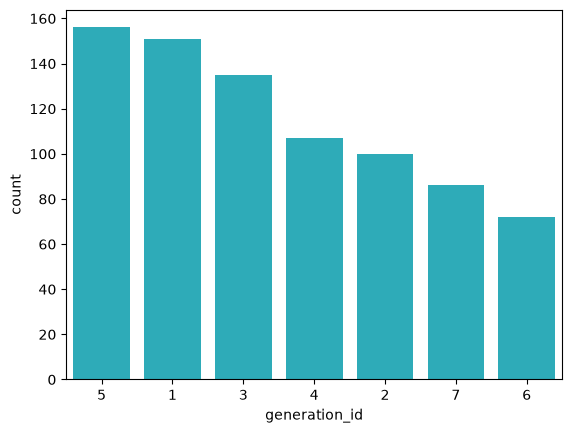

In [27]:
base_color = sb.color_palette()[9]
gen_order = pokemon['generation_id'].value_counts().index


sb.countplot(data = pokemon, x = 'generation_id', color=base_color, order=gen_order);

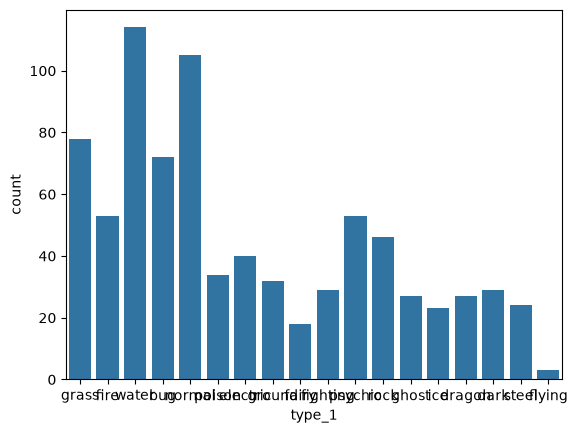

In [31]:
sb.countplot(data = pokemon, x = 'type_1');

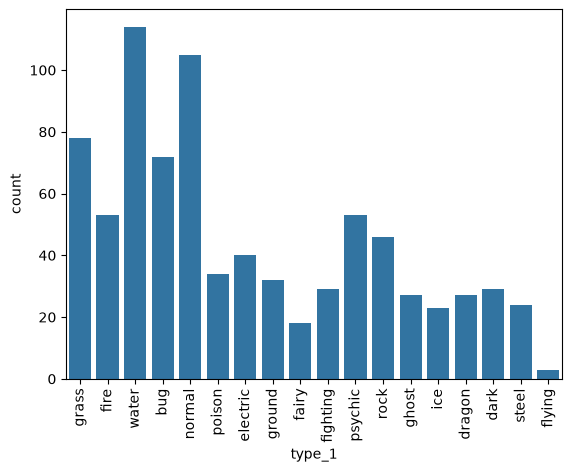

In [32]:
sb.countplot(data = pokemon, x = 'type_1');
plt.xticks(rotation = 90);

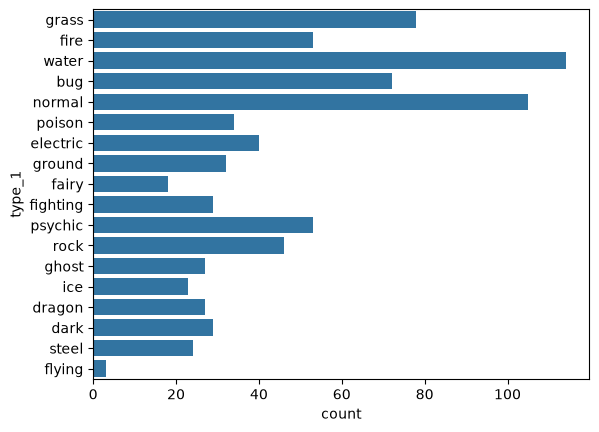

In [7]:
sb.countplot(data = pokemon, y = 'type_1');

<Axes: xlabel='count', ylabel='type_1'>

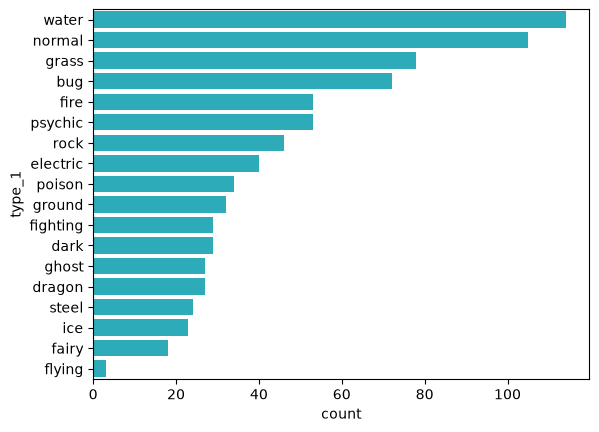

In [8]:
type_order = pokemon['type_1'].value_counts().index
sb.countplot(data = pokemon, y = 'type_1', order = type_order, color = base_color)

<Axes: xlabel='count', ylabel='type_2'>

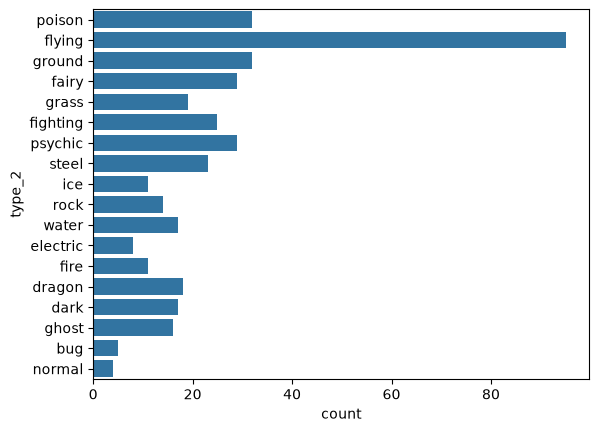

In [9]:
sb.countplot(data = pokemon, y = 'type_2')

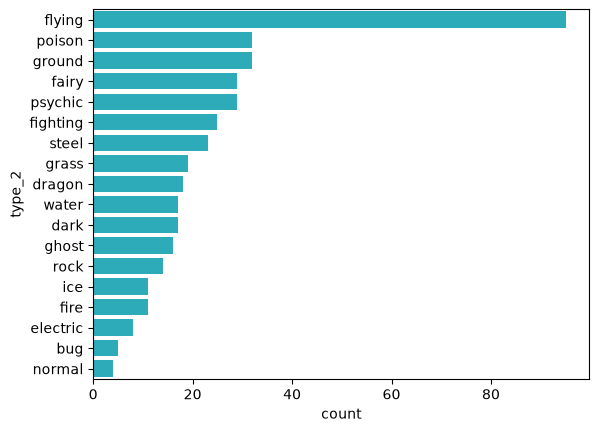

In [10]:

order_type2 = pokemon['type_2'].value_counts().index
sb.countplot(data = pokemon, y = 'type_2', order = order_type2, color = base_color);

Bar Chart using the Matplotlib

You can even create a similar bar chart using the Matplotlib, instead of Seaborn. We will use the matplotlib.pyplot.bar()(opens in a new tab) function to plot the chart. The syntax is:

Create a vertical bar chart using Matplotlib, with a uniform single color

[1 2 3 4 5 6 7]
generation_id
1    151
2    100
3    135
4    107
5    156
6     72
7     86
Name: count, dtype: int64


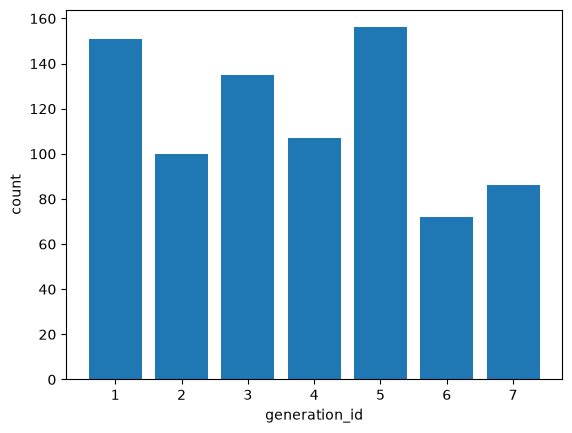

In [11]:
# Return the Series having unique values

x = pokemon['generation_id'].unique()

# Return the Series having frequency count of each unique value

y = pokemon['generation_id'].value_counts(sort=False)

print(x)
print(y)

plt.bar(x,y)

# Labeling the axes
plt.xlabel('generation_id')
plt.ylabel('count')

# Dsiplay the plot
plt.show()

There is a lot more you can do with both Seaborn and Matplotlib bar charts. The remaining examples will experiment with seaborn's countplot() function.

For nominal-type data, one common operation is to sort the data in terms of frequency. In the examples shown above, you can even order the bars as desirable. With our data in a pandas DataFrame, we can use various DataFrame methods to compute and extract an ordering, then set that ordering on the "order" parameter:

This can be done by using the order argument of the countplot() function.

Example 4. Static and dynamic ordering of the bars in a bar chart using seaborn.countplot()

<Axes: xlabel='generation_id', ylabel='count'>

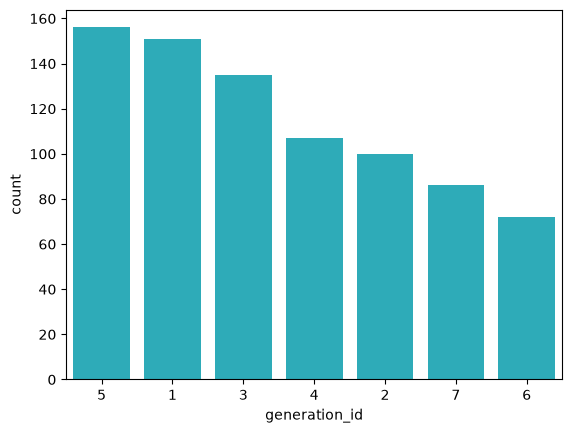

In [12]:
# Static-ordering the bars

sb.countplot(data=pokemon, x='generation_id', color=base_color, order=[5,1,3,4,2,7,6])

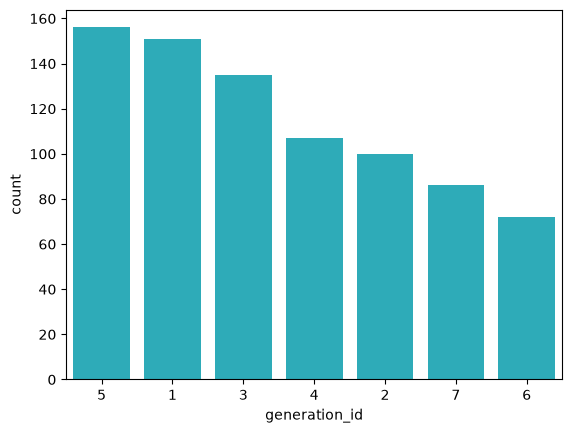

In [13]:
# Dynamic-ordering the bars
# The order of the display of the bars can be computed with the following logic.
# Count the frequency of each unique value in the 'generation_id' column, and sort it in descending order
# Returns a Series

freq = pokemon['generation_id'].value_counts()

# Get the indexes of the Series
gen_order = freq.index

# Plot the bar chart in the decreasing order of the frequency of the `generation_id`
sb.countplot(data=pokemon, x='generation_id', color=base_color, order=gen_order)
plt.show()

While we could sort the levels by frequency like above, we usually care about whether the most frequent values are at high levels, low levels, etc. For ordinal-type data, we probably want to sort the bars in order of the variables. The best thing for us to do in this case is to convert the column into an ordered categorical data type.

Additional Variation - Refer to the CategoricalDtype(opens in a new tab) to convert the column into an ordered categorical data type. to convert the column into an ordered categorical data type. By default, pandas reads in string data as object types, and will plot the bars in the order in which the unique values were seen. By converting the data into an ordered type, the order of categories becomes innate to the feature, and we won't need to specify an "order" parameter each time it's required in a plot.

Should you find that you need to sort an ordered categorical type in a different order, you can always temporarily override the data type by setting the "order" parameter as above.

The category labels in the examples above are very small. In case, the category labels have large names, you can make use of the matplotlib.pyplot.xticks(rotation=90) function, which will rotate the category labels (not axes) counter-clockwise 90 degrees.

Absolute vs. Relative Frequency
By default, seaborn's countplot function will summarize and plot the data in terms of absolute frequency, or pure counts. In certain cases, you might want to understand the distribution of data or want to compare levels in terms of the proportions of the whole. In this case, you will want to plot the data in terms of relative frequency, where the height indicates the proportion of data taking each level, rather than the absolute count.

One method of plotting the data in terms of relative frequency on a bar chart is to just relabel the count's axis in terms of proportions. The underlying data will be the same, it will simply be the scale of the axis ticks that will be changed.

Example 1. Demonstrate data wrangling, and plot a horizontal bar chart.

Example 1 - Step 1. Make the necessary import

In [14]:
print(pokemon.shape)
pokemon.head()


(807, 14)


,id,species,generation_id,height,weight,base_experience,type_1,type_2,hp,attack,defense,speed,special-attack,special-defense
0,1,bulbasaur,1,0.7,6.9,64,grass,poison,45,49,49,45,65,65
1,2,ivysaur,1,1.0,13.0,142,grass,poison,60,62,63,60,80,80
2,3,venusaur,1,2.0,100.0,236,grass,poison,80,82,83,80,100,100
3,4,charmander,1,0.6,8.5,62,fire,NaN,39,52,43,65,60,50
4,5,charmeleon,1,1.1,19.0,142,fire,NaN,58,64,58,80,80,65


Last time we created the bar chart of pokemon by their type_1. Let's club the rows of both type_1 and type_2, so that the resulting dataframe has new column, type_level

This operation will double the number of rows in pokemon from 807 to 1614

Data Wrangling Step

We will use the pandas.DataFrame.melt() method to unpivot a DataFrame from wide to long format, optionally leaving identifiers set. The syntax is:

DataFrame.melt(id_vars, value_vars, var_name, value_name, col_level, ignore_index)

It is essential to understand the parameters involved:

1. id_vars - It is a tuple representing the column(s) to use as identifier variables.
2. value_vars - It is tuple representing the column(s) to unpivot (remove, out of place).
3. var_name - It is a name of the new column.
4. value_name - It is a name to use for the ‘value’ of the columns that are unpivoted.
Refer here(opens in a new tab) for more details on the parameters.

The function below will do the following in the pokemon dataframe out of place:

1. Select the 'id', and 'species' columns from pokemon.
2. Remove the 'type_1', 'type_2' columns from pokemon
3. Add a new column 'type_level' that can have a value either 'type_1' or 'type_2'
4. Add another column 'type' that will contain the actual value contained in the 'type_1', 'type_2' columns. For example, the first row in the pokemon dataframe having id=1 and species=bulbasaur will now occur twice in the resulting dataframe after the melt() operation. The first occurrence will have type=grass, whereas, the second occurrence will have type=poison.

Example 1 - Step 2. Data wrangling to reshape the pokemon dataframe

In [15]:
pokemon.head()

,id,species,generation_id,height,weight,base_experience,type_1,type_2,hp,attack,defense,speed,special-attack,special-defense
0,1,bulbasaur,1,0.7,6.9,64,grass,poison,45,49,49,45,65,65
1,2,ivysaur,1,1.0,13.0,142,grass,poison,60,62,63,60,80,80
2,3,venusaur,1,2.0,100.0,236,grass,poison,80,82,83,80,100,100
3,4,charmander,1,0.6,8.5,62,fire,NaN,39,52,43,65,60,50
4,5,charmeleon,1,1.1,19.0,142,fire,NaN,58,64,58,80,80,65


In [ ]:
pkmn_types = pokemon.melt(id_vars=['id', 'species'], value_vars=['type_1', 'type_2'], var_name='type_level', value_name='type')
print(pkmn_types.shape)

print(pkmn_types.head())
print(pkmn_types.tail())


(1614, 4)
   id     species type_level   type
0   1   bulbasaur     type_1  grass
1   2     ivysaur     type_1  grass
2   3    venusaur     type_1  grass
3   4  charmander     type_1   fire
4   5  charmeleon     type_1   fire
       id      species type_level    type
1609  803      poipole     type_2     NaN
1610  804    naganadel     type_2  dragon
1611  805    stakataka     type_2   steel
1612  806  blacephalon     type_2   ghost
1613  807      zeraora     type_2     NaN


In [17]:
print(pkmn_types['type_level'].unique())
print()
print(pkmn_types['type'].unique())

<StringArray>
['type_1', 'type_2']
Length: 2, dtype: str

<StringArray>
[   'grass',     'fire',    'water',      'bug',   'normal',   'poison',
 'electric',   'ground',    'fairy', 'fighting',  'psychic',     'rock',
    'ghost',      'ice',   'dragon',     'dark',    'steel',   'flying',
        nan]
Length: 19, dtype: str


Example 1 - Step 3. Find the frequency of unique values in the type column

In [18]:
# Count the frequency of unique values in the `type` column of pkmn_types dataframe. 
# By default, returns the decreasing order of the frequency.

type_counts = pkmn_types['type'].value_counts()
type_counts

type
water       131
normal      109
flying       98
grass        97
psychic      82
bug          77
poison       66
fire         64
ground       64
rock         60
fighting     54
electric     48
fairy        47
steel        47
dark         46
dragon       45
ghost        43
ice          34
Name: count, dtype: int64

In [19]:
# Get the unique values of the `type` column, in the decreasing order of the frequency.

type_order = type_counts.index
type_order

Index(['water', 'normal', 'flying', 'grass', 'psychic', 'bug', 'poison',
       'fire', 'ground', 'rock', 'fighting', 'electric', 'fairy', 'steel',
       'dark', 'dragon', 'ghost', 'ice'],
      dtype='str', name='type')

Example 1 - Step 4. Plot the horizontal bar charts

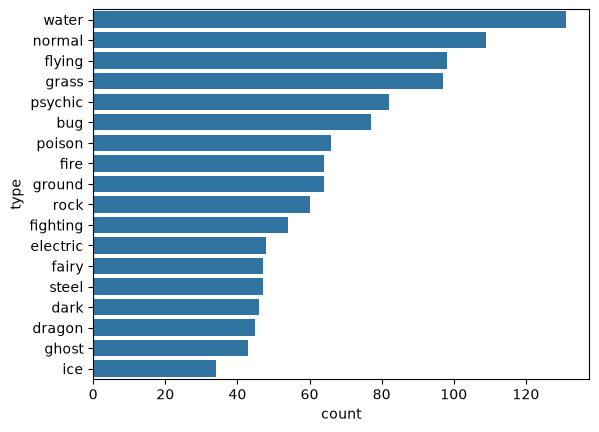

In [20]:
base_color = sb.color_palette()[0]
sb.countplot(data=pkmn_types, y='type', color=base_color, order=type_order);

Example 2. Plot a bar chart having the proportions, instead of the actual count, on one of the axes.
Example 2 - Step 1. Find the maximum proportion of bar

The goal of Example 2: label the bars with proportions (like 0.10) instead of raw counts. A proportion is count ÷ total, so we need a total and the biggest count.

In [39]:
print(pkmn_types.head())
print(type_counts)

   id     species type_level   type
0   1   bulbasaur     type_1  grass
1   2     ivysaur     type_1  grass
2   3    venusaur     type_1  grass
3   4  charmander     type_1   fire
4   5  charmeleon     type_1   fire
type
water       131
normal      109
flying       98
grass        97
psychic      82
bug          77
poison       66
fire         64
ground       64
rock         60
fighting     54
electric     48
fairy        47
steel        47
dark         46
dragon       45
ghost        43
ice          34
Name: count, dtype: int64


In [45]:
# Returns the sum of all not-null values in `type` column
n_pokemon = pkmn_types['type'].value_counts().sum()
n_pokemon

np.int64(1212)

In [53]:
# Return the highest frequency in the `type` column
# iloc[0] retrieves the value at position 0 (the first item) in the Series

max_type_count = type_counts.iloc[0]
print(max_type_count)

#or using the .max() method

max_type_count = type_counts.max()
print(max_type_count)

131
131


In [54]:
# Return the maximum proportion, or in other words, 
# compute the length of the longest bar in terms of the proportion

#propotions is always part / whole

max_prop = max_type_count / n_pokemon
print(max_prop)

0.10808580858085809


Example 2 - Step 2. Create an array of evenly spaced, proportioned values

In [60]:
# Use numpy.arange() function to produce a set of evenly spaced proportioned values 
# between 0 and max_prop, with a step size 0.02

tick_props = np.arange(0, max_prop, 0.02)
tick_props

array([0.  , 0.02, 0.04, 0.06, 0.08, 0.1 ])

We need x-tick labels that must be evenly spaced on the x-axis. For this purpose, we must have a list of labels ready with us, before using it with plt.xticks() function.

Example 2 - Step 3. Create a list of String values that can be used as tick labels.

In [61]:
# Use a list comprehension to create tick_names that we will apply to the tick labels. 
# Pick each element `v` from the `tick_props`, and convert it into a formatted string.
# `{:0.2f}` denotes that before formatting, we 2 digits of precision and `f` is used to represent floating point number.
# Refer [here](https://docs.python.org/2/library/string.html#format-string-syntax) for more details

tick_names = ['{:0.2f}'.format(v) for v in tick_props]
print(tick_names)

['0.00', '0.02', '0.04', '0.06', '0.08', '0.10']


We already have the labels, tick_names. For the positions, remember that the bars are still drawn by count, so the mark for '0.02' has to sit at the count that is 0.02 of 1,212. That’s 0.02 × 1212 = 24.24. A NumPy array times a number multiplies every item:

In [62]:
print(tick_props * n_pokemon)

[  0.    24.24  48.48  72.72  96.96 121.2 ]


Text(0.5, 0, 'proportion')

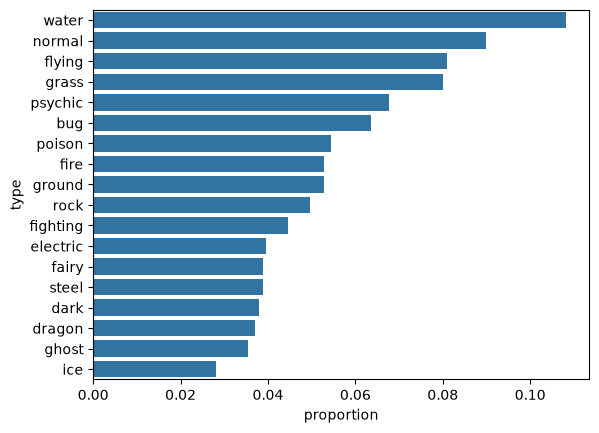

In [63]:
sb.countplot(data=pkmn_types, y='type', order=type_order)

plt.xticks(tick_props * n_pokemon, tick_names)
plt.xlabel('proportion')

Additional Variation
Rather than plotting the data on a relative frequency scale, you might use text annotations to label the frequencies on bars instead. This requires writing a loop over the tick locations and labels and adding one text element for each bar.

Example 3. Print the text (proportion) on the bars of a horizontal plot.

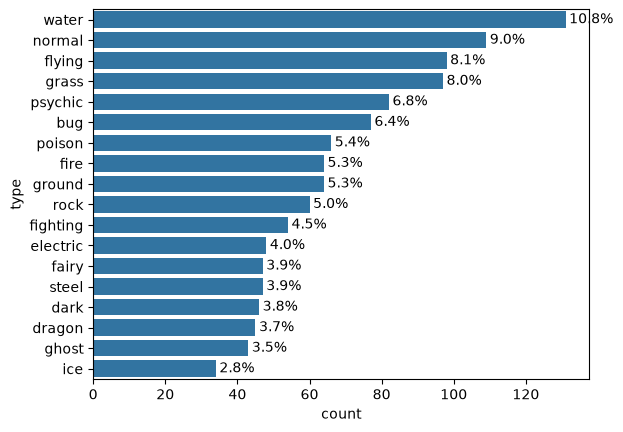

In [66]:
# Considering the same chart from the Example 1 above, print the text (proportion) on the bars

sb.countplot(data=pkmn_types, y='type', order=type_order)


# Logic to print the proportion text on the bars

for i in range (type_counts.shape[0]):
    # Remember, type_counts contains the frequency of unique values in the `type` column in decreasing order.
    count = type_counts.iloc[i]
    # Convert count into a percentage, and then into string
    pct_string = '{:0.1f}%'.format(100*count / n_pokemon)
    # Print the string value on the bar. 
    # Read more about the arguments of text() function [here](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.text.html)
    plt.text(count+1, i, pct_string, va='center')


Example 4. Print the text (proportion) below the bars of a Vertical plot.

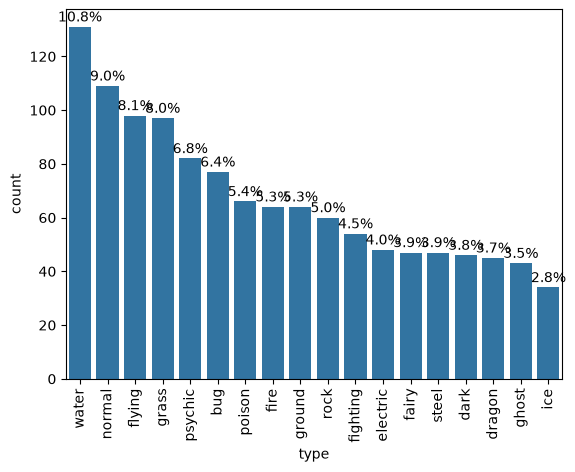

In [67]:
# Considering the same chart from the Example 1 above, print the text (proportion) BELOW the bars
base_color = sb.color_palette()[0]
sb.countplot(data=pkmn_types, x='type', color=base_color, order=type_order)


# Recalculating the type_counts just to have clarity.
type_counts = pkmn_types['type'].value_counts()

# get the current tick locations and labels
locs, labels = plt.xticks(rotation=90) 

# loop through each pair of locations and labels
for loc, label in zip(locs, labels):

    # get the text property for the label to get the correct count
    count = type_counts[label.get_text()]
    pct_string = '{:0.1f}%'.format(100*count/n_pokemon)

    # print the annotation just below the top of the bar
    plt.text(loc, count+2, pct_string, ha = 'center', color = 'black')

I use the .get_text() method to obtain the category name, so I can get the count of each category level. At the end, I use the text(opens in a new tab) function to print each percentage, with the x-position, y-position, and string as the three main parameters to the function.

Tip - Is the text on the bars not readable clearly? Consider changing the size of the plot by using the following:

In [68]:
from matplotlib import rcParams
# Specify the figure size in inches, for both X, and Y axes
rcParams['figure.figsize'] = 12,8